# RSW / 03 — Does the time spent in a regime matter? Hazard, HSMM vs HMM, direction by age (2020-01 – 2023-06)

Protocol: [`RSW 005`](../../discussions/MNQ_Regime_Switching/005_claude_rsw03_duration_preregistration.md). z is the RSW 01 series. The event is |z| ≥ u(0.96), as in RSW 02.

- **A — HA**: the exceedance hazard rises with the time since the last exceedance (log-log slope over 13–480 bars) beyond the chain, M1 and M2 hazards (day-block 95% bound).
- **B**: explicit-duration HSMM (discrete Weibull or negative-binomial durations, ages 1–60 plus a tail) against the HMM with the same states.
  - **HB1**: better out-of-sample z density (Holm across 4).
  - **HB2**: better next-bar exceedance forecast (Holm across 4).
  - **HB3**: a duration shape ≠ 1 (|t| ≥ 3, same sign) in all three fits.
- **C**: HSMM with age drift c_s + b_s log d.
  - **HC1**: b_s with |t| ≥ 3, same sign in all fits.
  - **HC2 = R4**: beats zero and the part B model.
  - **HC3 = E**: one-bar trade after 3 ticks.

In [1]:
import json, os, sys, tempfile, pickle
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("RSW_SYNTHETIC") == "1"
SYNTH_HSMM = os.environ.get("RSW_SYNTH_HSMM") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("RSW_SYNTH_DIR") or tempfile.mkdtemp(prefix="rsw_")
    os.environ["RSW_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import mnq_predict as P
from equity_trading import reversal as V
from equity_trading import regime_ar as R
from equity_trading import hawkes as H
from equity_trading import hsmm as HS
from equity_trading import micro_bars as MB

CFG = P.SYNTH_CFG if SYNTHETIC else P.MRPConfig()
RC, HC = R.RSWConfig(), HS.HSMMConfig()
D = dt.date
OUT = Path("03"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
print("engines", HS.HSMM_VERSION, H.HWK_VERSION, R.RSW_VERSION, P.MRP_VERSION,
      ("| synthetic " + ("hsmm" if SYNTH_HSMM else "markov")) if SYNTHETIC else "| real data")
if SYNTHETIC and not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
    if SYNTH_HSMM:
        HS.write_synthetic_hsmm(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.train[1], CFG)
    else:
        R.write_synthetic_regimes(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.train[1], CFG)

engines 0.1.0 0.1.0 0.1.0 0.1.1 | real data


In [2]:
if SYNTHETIC:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2020, 7, 1)), CFG.refits_train, CFG.train[1]
    PERIODS = {"2020Q3": (D(2020, 7, 1), D(2020, 9, 30)), "2020Q4": (D(2020, 10, 1), D(2020, 12, 31))}
else:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2021, 1, 1)), CFG.refits_train, CFG.train[1]
    PERIODS = {"2021": (D(2021, 1, 1), D(2021, 12, 31)), "2022": (D(2022, 1, 1), D(2022, 12, 31)),
               "2023H1": (D(2023, 1, 1), D(2023, 6, 30))}
NEED_PERIODS = int(np.ceil(2 / 3 * len(PERIODS)))
grid = P.load_grid(CFG.warmup_start, END, CFG)
sig2 = V.event_sigma(grid, FIRST_FIT, REFITS, END, CFG)
m1 = MB.load_1m(CFG.root, CFG.warmup_start - dt.timedelta(days=3), END + dt.timedelta(days=1))
S = R.build_series(grid, sig2, m1, CFG, RC)
S = S[(S["trade_date"] >= CFG.train[0]) & (S["trade_date"] <= END)]
del m1, grid
td = S["trade_date"].to_numpy(); obs = S["obs"].to_numpy(bool); ALL = np.ones(len(S), bool)
print(f"{len(S):,} bars | observed {obs.sum():,} | CME days {S['trade_date'].nunique()}")

243,984 bars | observed 236,025 | CME days 884


## A. Model-free hazard of an exceedance by bars since the last one

,lo,hi,mid,events,rows,h,h_M1,h_M2
0,1,1,1.00000,790.0,9411.0,0.08394,0.11450,0.09306
1,2,2,2.00000,488.0,8582.0,0.05686,0.05745,0.04687
2,3,3,3.00000,393.0,8075.0,0.04867,0.03882,0.04111
3,4,4,4.00000,331.0,7666.0,0.04318,0.03624,0.03791
4,5,5,5.00000,314.0,7358.0,0.04267,0.03452,0.03870
5,6,6,6.00000,339.0,7047.0,0.04811,0.03453,0.03871
6,7,7,7.00000,274.0,6700.0,0.04090,0.03510,0.03675
7,8,8,8.00000,244.0,6390.0,0.03818,0.03516,0.03764
8,9,9,9.00000,237.0,6117.0,0.03874,0.03463,0.03742
9,10,10,10.00000,234.0,5900.0,0.03966,0.03418,0.03594


u = 2.122 | slope of log h on log age over (13, 480): -0.1448 [-0.1840, -0.1089] | null slopes {'chain': 0.0, 'M1': 0.0032, 'M2': -0.0365}
HA (rising beyond every Markov null): False | falling below every null: True | elapsed 0:01:35.251908


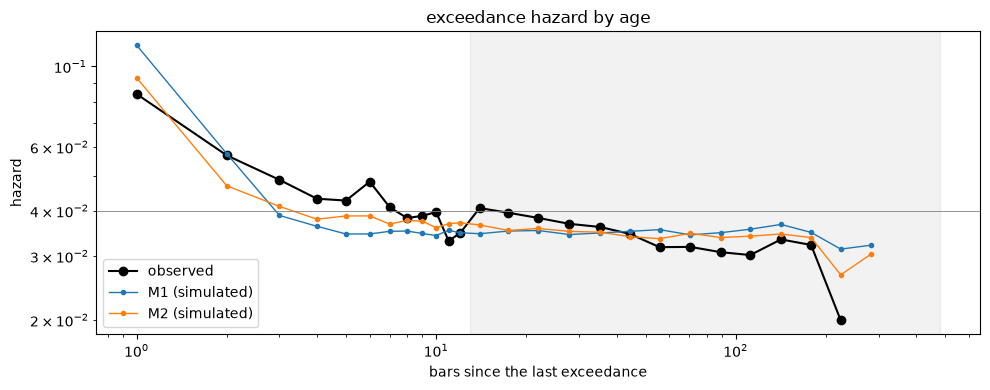

In [3]:
t0 = dt.datetime.now()
FULL = {K: R.fit(S, K, False, ALL, RC) for K in (2, 3)}
u_all = H.threshold(S, ALL, HC.q)
NULL = {f"M{K - 1}": HS.null_hazard(m, u_all, HC) for K, m in FULL.items()}
HA_RES = HS.hazard_test(S, u_all, NULL, HC)
hc = HA_RES["curve"]
display(hc.assign(**{f"h_{k}": v["h"].to_numpy() for k, v in NULL.items()}).round(5))
print(f"u = {u_all:.3f} | slope of log h on log age over {HC.slope_range}: {HA_RES['slope']:.4f} "
      f"[{HA_RES['slope_lo95']:.4f}, {HA_RES['slope_hi95']:.4f}] | null slopes",
      {k: round(v, 4) for k, v in HA_RES["null_slopes"].items()})
HA = HA_RES["HA_rising"]
print("HA (rising beyond every Markov null):", HA, "| falling below every null:", HA_RES["falling_vs_all"],
      "| elapsed", dt.datetime.now() - t0)
fig, ax = plt.subplots(figsize=(10, 4))
ok = hc["rows"] >= HC.min_bin_obs
ax.plot(hc.loc[ok, "mid"], hc.loc[ok, "h"], marker="o", color="k", label="observed")
for k, v in NULL.items():
    o2 = v["rows"] >= HC.min_bin_obs
    ax.plot(v.loc[o2, "mid"], v.loc[o2, "h"], marker=".", lw=1, label=f"{k} (simulated)")
ax.axhline(HA_RES["curve"]["events"].sum() / HA_RES["curve"]["rows"].sum(), color="grey", lw=0.6)
ax.axvspan(*HC.slope_range, color="grey", alpha=0.1)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("bars since the last exceedance"); ax.set_ylabel("hazard")
ax.legend(); ax.set_title("exceedance hazard by age"); plt.tight_layout(); plt.savefig(OUT / "hazard.png", dpi=110); plt.show()

## B and C. Walk-forward: HMM vs HSMM (WB, NB) and the age-drift HSMM (WB)

In [4]:
cache = OUT / f"fits_{HS.HSMM_VERSION}{'_synth' if SYNTHETIC else ''}{'_hsmm' if SYNTH_HSMM else ''}.pkl"
FITS = pickle.load(open(cache, "rb")) if cache.exists() else {}
def save():
    pickle.dump(FITS, open(cache, "wb"))
MODELS = [(f"{fam}{K}", K, fam, False) for K in (2, 3) for fam in HC.families] + [(f"AGE{K}", K, "WB", True) for K in (2, 3)]
edges = list(REFITS) + [END + dt.timedelta(days=1)]
for a in REFITS:
    fm = td < a
    for K in (2, 3):
        key = ("HMM", K, str(a))
        if key not in FITS:
            t0 = dt.datetime.now(); FITS[key] = R.fit(S, K, False, fm, RC); save()
            print(f"HMM K={K} before {a}: {dt.datetime.now() - t0}")
    for name, K, fam, age in MODELS:
        key = (name, K, str(a))
        if key in FITS:
            continue
        t0 = dt.datetime.now()
        warm = FITS[(f"WB{K}", K, str(a))] if age else None
        FITS[key] = HS.fit(S, fm, FITS[("HMM", K, str(a))], fam, age, HC, warm=warm)
        save()
        f = FITS[key]
        print(f"{name} before {a}: loglik {f.loglik:.1f} (HMM {FITS[('HMM', K, str(a))].loglik:.1f}) | "
              f"iter {f.n_iter} conv {f.converged} | {dt.datetime.now() - t0}")

AGE3 before 2022-01-01: loglik -189810.9 (HMM -189968.2) | iter 300 conv False | 0:07:59.312427
HMM K=2 before 2023-01-01: 0:00:18.513213
HMM K=3 before 2023-01-01: 0:00:53.353271
WB2 before 2023-01-01: loglik -278403.2 (HMM -278551.4) | iter 60 conv True | 0:00:32.737511
NB2 before 2023-01-01: loglik -278424.6 (HMM -278551.4) | iter 64 conv True | 0:00:37.113227
WB3 before 2023-01-01: loglik -276832.6 (HMM -277237.2) | iter 300 conv False | 0:04:27.921041
NB3 before 2023-01-01: loglik -276984.0 (HMM -277237.2) | iter 300 conv False | 0:04:36.752824
AGE2 before 2023-01-01: loglik -278395.8 (HMM -278551.4) | iter 10 conv True | 0:00:13.678698
AGE3 before 2023-01-01: loglik -276763.0 (HMM -277237.2) | iter 123 conv True | 0:04:33.421190


In [5]:
for name, K, fam, age in MODELS:
    for a in REFITS:
        f = FITS[(name, K, str(a))]
        print(f"--- {name} before {a}: loglik gain over HMM {f.loglik - FITS[('HMM', K, str(a))].loglik:.1f}")
        display(f.table().round(4))

--- WB2 before 2021-01-01: loglik gain over HMM 62.7


,c,phi,sd,b_age,t_b_age,shape,t_shape_vs_1,mean_duration,h1,h10
state,,,,,,,,,,
0,0.0469,-0.0556,0.8140,0.0,NaN,0.7518,-26.3398,10.2269,0.1862,0.0848
1,-0.2165,0.1745,1.8388,0.0,NaN,0.5114,-30.3949,1.5016,0.7990,0.2391


--- WB2 before 2022-01-01: loglik gain over HMM 163.8


,c,phi,sd,b_age,t_b_age,shape,t_shape_vs_1,mean_duration,h1,h10
state,,,,,,,,,,
0,0.0454,-0.0549,0.7941,0.0,NaN,0.6164,-60.9194,9.7791,0.2729,0.0795
1,-0.2046,0.1464,1.8387,0.0,NaN,0.7664,-21.8940,1.6047,0.6844,0.4069


--- WB2 before 2023-01-01: loglik gain over HMM 148.2


,c,phi,sd,b_age,t_b_age,shape,t_shape_vs_1,mean_duration,h1,h10
state,,,,,,,,,,
0,0.0314,-0.0429,0.8152,0.0,NaN,0.6693,-55.5333,13.3368,0.1955,0.0668
1,-0.2161,0.1502,2.0629,0.0,NaN,0.8346,-15.4148,1.5220,0.6942,0.4941


... (26 outputs left out)

--- AGE3 before 2022-01-01: loglik gain over HMM 157.3


,c,phi,sd,b_age,t_b_age,shape,t_shape_vs_1,mean_duration,h1,h10
state,,,,,,,,,,
0,0.1585,-0.0843,0.6588,-0.0459,-19.2896,0.6902,-39.7957,7.0526,0.2782,0.1060
1,-0.0287,-0.0117,1.0357,0.0038,1.2853,0.4477,-74.3853,7.7561,0.4602,0.0766
2,-0.2168,0.2286,2.2989,-0.1097,-2.3854,0.5138,-25.8153,1.3434,0.8414,0.2714


--- AGE3 before 2023-01-01: loglik gain over HMM 474.3


,c,phi,sd,b_age,t_b_age,shape,t_shape_vs_1,mean_duration,h1,h10
state,,,,,,,,,,
0,0.0795,-0.0808,0.6133,-0.0208,-11.1667,0.4834,-103.5591,2.7561,0.6364,0.1418
1,0.0081,0.0037,1.0840,-0.0144,-6.4343,0.3266,-137.9979,3.3485,0.7359,0.0911
2,-0.2949,0.2185,3.0188,-0.1493,-1.6890,0.6194,-16.2930,1.3431,0.8140,0.3575


In [6]:
# out-of-sample paths for every model: frozen params per segment, causal filter from the start
OOS = {}
segs = []
for a, b in zip(edges[:-1], edges[1:]):
    seg = (td >= a) & (td < b)
    u = H.threshold(S, td < a, HC.q)
    segs.append((a, seg, u))
def collect(name, K, is_hmm):
    parts = []
    for a, seg, u in segs:
        f = FITS[("HMM" if is_hmm else name, K, str(a))]
        if is_hmm:
            fr = R.filter_run(S, f)
            p = pd.DataFrame({"fc": fr["fc"], "lpz": fr["lpz"], "pexc": H.prob_msar(S, f, u)}, index=S.index)
        else:
            p = HS.filter_run(S, f, u)[["fc", "lpz", "pexc", "age"]]
        p["u"] = u
        parts.append(p[seg])
    return pd.concat(parts)
for K in (2, 3):
    OOS[f"HMM{K}"] = collect(None, K, True)
for name, K, fam, age in MODELS:
    OOS[name] = collect(name, K, False)
Sx = S[td >= REFITS[0]]
o = Sx["obs"].to_numpy(bool)
day = Sx["trade_date"].to_numpy()
z = np.where(o, Sx["z"], np.nan)
e = {k: ((np.abs(Sx["z"].to_numpy()) >= v["u"].to_numpy()) & o).astype(float) for k, v in OOS.items()}
print("out-of-sample observed bars", o.sum(), "| exceedances", int(e["HMM2"].sum()))

out-of-sample observed bars 167771 | exceedances 6524


In [7]:
rows, p1, p2 = [], {}, {}
for name, K, fam, age in MODELS:
    if age:
        continue
    b = f"HMM{K}"
    lp, lpb = OOS[name]["lpz"].to_numpy(), OOS[b]["lpz"].to_numpy()
    d1 = R.predictive_dm(np.where(o, lp, np.nan), np.where(o, lpb, np.nan), day, HC.nw_lags)
    sc, scb = H.bernoulli_score(OOS[name]["pexc"].to_numpy(), e[name]), H.bernoulli_score(OOS[b]["pexc"].to_numpy(), e[b])
    d2 = H.score_dm(np.where(o, sc, np.nan), np.where(o, scb, np.nan), day, HC.nw_lags)
    shp = {k: [FITS[(name, K, str(a))].shape_t(k) for a in REFITS] for k in range(K)}
    sh = {k: [round(float(HS.shape_param(fam, FITS[(name, K, str(a))].th[k])), 3) for a in REFITS] for k in range(K)}
    hb3_states = [k for k in range(K) if all(abs(t) >= HC.t_dur for t in shp[k]) and len({np.sign(t) for t in shp[k]}) == 1]
    rows.append({"model": name, "vs": b, "density_gain_per_bar": d1["per_bar_diff"], "HB1_t": d1["t"], "HB1_p": d1["p"],
                 "exc_gain_per_bar": d2["per_bar_diff"], "HB2_t": d2["t"], "HB2_p": d2["p"],
                 "shape_by_state_fit": sh, "t_shape_by_state_fit": {k: [round(t, 1) for t in v] for k, v in shp.items()},
                 "HB3_states": hb3_states, "HB3": bool(hb3_states)})
    p1[name], p2[name] = d1["p"], d2["p"]
GB = pd.DataFrame(rows).set_index("model")
GB["HB1_p_holm"] = pd.Series(R.holm(p1)); GB["HB2_p_holm"] = pd.Series(R.holm(p2))
GB["HB1"] = (GB["density_gain_per_bar"] > 0) & (GB["HB1_p_holm"] <= HC.alpha)
GB["HB2"] = (GB["exc_gain_per_bar"] > 0) & (GB["HB2_p_holm"] <= HC.alpha)
display(GB.T)

model,WB2,NB2,WB3,NB3
vs,HMM2,HMM2,HMM3,HMM3
density_gain_per_bar,0.000442,0.000377,0.000537,0.000272
HB1_t,2.832532,2.827302,2.899115,2.08601
HB1_p,0.002309,0.002347,0.001871,0.018489
exc_gain_per_bar,0.000191,0.000182,0.000049,0.000041
HB2_t,1.665889,1.800125,0.604054,0.569841
HB2_p,0.047868,0.03592,0.272904,0.284393
shape_by_state_fit,"{0: ['0.752', '0.616', '0.669'], 1: ['0.511', ...","{0: ['0.559', '0.405', '0.491'], 1: ['0.201', ...","{0: ['0.893', '0.739', '0.564'], 1: ['0.686', ...","{0: ['0.871', '0.647', '0.436'], 1: ['0.47', '..."
t_shape_by_state_fit,"{0: ['-26.3', '-60.9', '-55.5'], 1: ['-30.4', ...","{0: ['-29.6', '-64.8', '-56.6'], 1: ['-35.7', ...","{0: ['-7.3', '-26.0', '-83.8'], 1: ['-15.8', '...","{0: ['-4.7', '-19.7', '-60.6'], 1: ['-19.9', '..."
HB3_states,"[0, 1]","[0, 1]","[0, 1, 2]","[0, 1, 2]"


In [8]:
rows, pcw = [], {}
for name, K, fam, age in MODELS:
    if not age:
        continue
    base = f"WB{K}"
    fc, fcb = OOS[name]["fc"].to_numpy(), OOS[base]["fc"].to_numpy()
    sc = R.forecast_scores(z, fc, fcb, day, HC.nw_lags)
    sc0 = R.forecast_scores(z, fc, np.zeros_like(fc), day, HC.nw_lags)
    tb = {k: [round(float(FITS[(name, K, str(a))].b[k] / FITS[(name, K, str(a))].b_se[k]), 2) for a in REFITS] for k in range(K)}
    bb = {k: [round(float(FITS[(name, K, str(a))].b[k]), 4) for a in REFITS] for k in range(K)}
    hc1 = [k for k in range(K) if all(abs(t) >= HC.t_dur for t in tb[k]) and len({np.sign(t) for t in tb[k]}) == 1]
    rows.append({"model": name, "vs": base, "b_by_state_fit": bb, "t_b_by_state_fit": tb, "HC1_states": hc1, "HC1": bool(hc1),
                 "r2_vs_zero": sc0["r2_oos_vs_zero"], "r2_vs_base": sc["r2_oos_vs_M0"], "CW_t": sc["cw_t"],
                 "CW_p": sc["cw_p"], "hit_rate": sc["hit_rate"]})
    pcw[name] = sc["cw_p"]
GC = pd.DataFrame(rows).set_index("model")
GC["CW_p_holm"] = pd.Series(R.holm(pcw))
GC["HC2"] = (GC["r2_vs_zero"] > 0) & (GC["r2_vs_base"] > 0) & (GC["CW_p_holm"] <= HC.alpha)
erows = []
for name, K, fam, age in MODELS:
    if not age:
        continue
    fc = OOS[name]["fc"].reindex(Sx.index).to_numpy()
    for thr, cost, lab in ((RC.cost_ticks, RC.cost_ticks, "gate: thr 3, cost 3"), (RC.realized_cost_ticks, RC.realized_cost_ticks, "thr 1.6, cost 1.6"),
                           (0.0, 0.0, "every bar, gross")):
        erows.append({"model": name, "rule": lab, **R.trade_stats(R.one_bar_trades(Sx, fc, thr), cost, PERIODS)})
E = pd.DataFrame(erows).set_index(["model", "rule"])
gate = E.xs("gate: thr 3, cost 3", level="rule").copy()
gate["p_holm"] = pd.Series(R.holm(gate["p"].fillna(1.0).to_dict()))
gate["periods_pos"] = sum((gate[f"net_{p}"] > 0).astype(int) for p in PERIODS)
gate["HC3"] = (gate["trades"] >= RC.min_trades) & (gate["net"] > 0) & (gate["p_holm"] <= HC.alpha) & (gate["periods_pos"] >= NEED_PERIODS)
GC = GC.join(gate[["HC3"]])
display(GC.T); display(E.round(3))

model,AGE2,AGE3
vs,WB2,WB3
b_by_state_fit,"{0: ['-0.0228', '-0.0174', '-0.0109'], 1: ['-0...","{0: ['-0.0576', '-0.0459', '-0.0208'], 1: ['0...."
t_b_by_state_fit,"{0: ['-7.52', '-9.08', '-6.73'], 1: ['-2.39', ...","{0: ['-14.59', '-19.29', '-11.17'], 1: ['1.76'..."
HC1_states,[0],[0]
HC1,True,True
r2_vs_zero,-0.000683,-0.001024
r2_vs_base,-0.000119,-0.00018
CW_t,-0.855929,0.140445
CW_p,0.803982,0.444154
hit_rate,0.502542,0.499472


trades  gross    net      t      p  win_rate  trades_per_day  net_usd_total_1c  net_2021  net_2022  net_2023H1
model rule                                                                                                                               
AGE2  gate: thr 3, cost 3    7139  0.964 -2.036 -1.700  0.955     0.472          12.416           -7268.5    -3.092    -1.434      -2.276
      thr 1.6, cost 1.6     22584  0.927 -0.673 -1.265  0.897     0.495          36.662           -7598.7    -2.342     0.368      -1.229
      every bar, gross     167771  0.261  0.261  2.280  0.011     0.503         270.163           21855.5    -0.142     0.492       0.642
AGE3  gate: thr 3, cost 3    6307 -0.421 -3.421 -2.816  0.998     0.468          11.283          -10789.0    -5.882    -1.862      -5.311
      thr 1.6, cost 1.6     22316  0.515 -1.085 -2.179  0.985     0.491          36.227          -12103.3    -1.586    -1.323       1.666
      every bar, gross     167771  0.226  0.226  1.913  0.028     0.499         270.163           18920.5    -0.098     0.502       0.365

## Descriptive: fitted hazards and filtered age

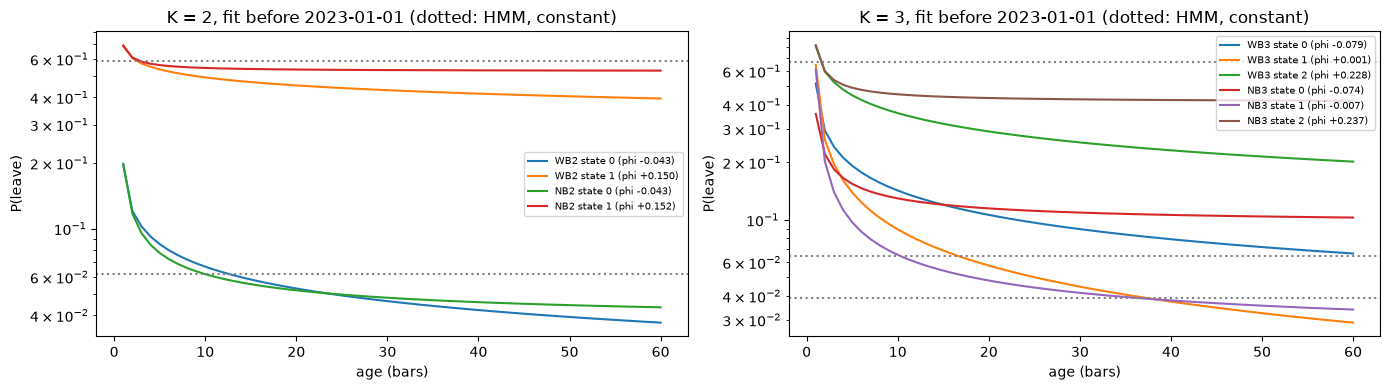

filtered expected age (WB2), out of sample: quantiles [ 4.   7.4 12.9 19.8 26.7 38.9]


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for i, K in enumerate((2, 3)):
    a = REFITS[-1]
    for name in (f"WB{K}", f"NB{K}"):
        f = FITS[(name, K, str(a))]
        for k in range(K):
            ax[i].plot(np.arange(1, HC.D + 1), f.hazards()[k], label=f"{name} state {k} (phi {f.phi[k]:+.3f})")
    hm = FITS[("HMM", K, str(a))]
    for k in range(K):
        ax[i].axhline(1 - hm.A[k, k], ls=":", color="grey")
    ax[i].set_yscale("log"); ax[i].set_xlabel("age (bars)"); ax[i].set_ylabel("P(leave)"); ax[i].legend(fontsize=7)
    ax[i].set_title(f"K = {K}, fit before {a} (dotted: HMM, constant)")
plt.tight_layout(); plt.savefig(OUT / "fitted_hazards.png", dpi=110); plt.show()
ag = OOS["WB2"]["age"].to_numpy()[o]
print("filtered expected age (WB2), out of sample: quantiles", np.round(np.quantile(ag, [.1, .25, .5, .75, .9, .99]), 1))

## Verdict

In [10]:
B_time = [m for m in GB.index if GB.loc[m, "HB2"] and GB.loc[m, "HB3"]]
B_dens = [m for m in GB.index if GB.loc[m, "HB1"] and GB.loc[m, "HB3"]]
C_ok = [m for m in GC.index if GC.loc[m, "HC1"] and GC.loc[m, "HC2"] and GC.loc[m, "HC3"]]
verdict = {
    "A": "RISING_HAZARD (a long calm makes an extreme more likely)" if HA else
         ("FALLING_HAZARD (not identified: heterogeneity / leftover volatility persistence also gives it)" if HA_RES["falling_vs_all"]
          else "NO_DURATION_EFFECT_IN_HAZARD"),
    "B": ("DURATION_DEPENDENCE_FORECASTS_TIMING: " + ", ".join(B_time)) if B_time else
         ("DURATION_DEPENDENCE_IN_DENSITY_ONLY: " + ", ".join(B_dens)) if B_dens else "HMM_SUFFICES",
    "C": ("CANDIDATE (2026 pre-registration): " + ", ".join(C_ok)) if C_ok else "NO_DIRECTION_BY_AGE"}
for k, v in verdict.items():
    print(k, v)
summary = {"study": "RSW 03", "engine": HS.HSMM_VERSION, "synthetic": SYNTHETIC, "synthetic_hsmm": SYNTH_HSMM,
           "A": {"u": u_all, "slope": HA_RES["slope"], "lo95": HA_RES["slope_lo95"], "hi95": HA_RES["slope_hi95"],
                 "null_slopes": HA_RES["null_slopes"], "HA": HA, "falling": HA_RES["falling_vs_all"],
                 "curve": json.loads(hc.to_json(orient="records"))},
           "fits": {f"{n}|{K}|{a}": (f.table().reset_index().to_dict(orient="records") if hasattr(f, "table") else None)
                    for (n, K, a), f in FITS.items()},
           "loglik": {f"{n}|{K}|{a}": float(f.loglik) for (n, K, a), f in FITS.items()},
           "B": json.loads(GB.to_json(orient="index", default_handler=str)),
           "C": json.loads(GC.to_json(orient="index", default_handler=str)),
           "trades": json.loads(E.reset_index().to_json(orient="records")), "verdict": verdict}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1, default=str)
print("written", OUT / "summary.json")

A FALLING_HAZARD (not identified: heterogeneity / leftover volatility persistence also gives it)
B DURATION_DEPENDENCE_IN_DENSITY_ONLY: WB2, NB2, WB3, NB3
C NO_DIRECTION_BY_AGE
written 03\summary.json
